# Day 24 — The Normal Distribution
### Statistics & Probability · Module 2 · Topic 2.4

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

**Session length:** 2 hours · 90 min concepts + 30 min practice

| # | What we cover | Time |
|---|---|---|
| 1 | The bell curve — what it is, and why it recurs | 20 min |
| 2 | 68 – 95 – 99.7 | 20 min |
| 3 | **Z-scores** — the SD as a ruler | 30 min |
| 4 | ⚠️ **When it does NOT apply** | 15 min |
| 5 | Mini build: a normality check you can trust | 5 min |
| 6 | **Practice notebook (separate file)** | 30 min |

---

## The step we take today

Yesterday a standard deviation of 15 was a **fact about your data**.

Today it becomes a **unit you can measure with**. "This value is 2 standard deviations above
the mean" means the same thing whether you are measuring IQ, rainfall or revenue — and that
is what makes every test in the rest of Module 2 possible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.simplefilter("ignore")

rng = np.random.default_rng(24)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 1.26.4 | pandas 2.2.3


---
# 1. The bell curve

Two numbers define the **entire** curve:

- **μ (mu)** sets *where* it sits
- **σ (sigma)** sets *how wide* it is

Nothing else about it can change. That is why one table of probabilities works for every
normal distribution in existence — and why z-scores work at all.

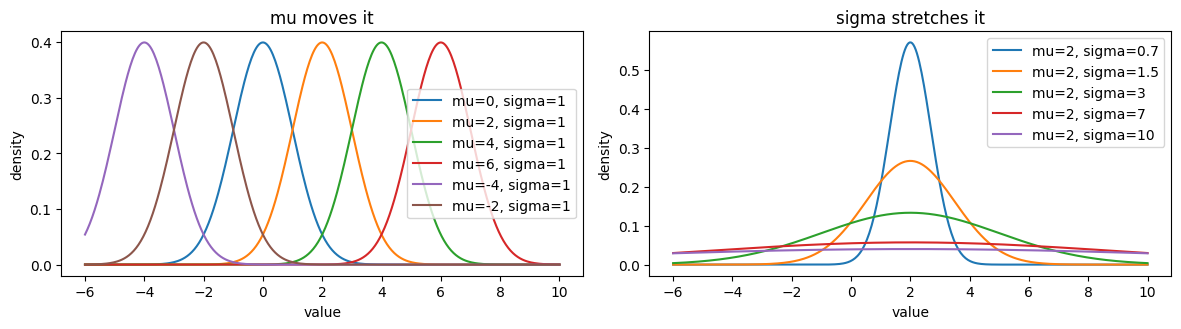

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
x = np.linspace(-6, 10, 400)

# changing mu slides it
for mu in [0, 2, 4,6,-4,-2]:
    axes[0].plot(x, stats.norm.pdf(x, mu, 1), label=f"mu={mu}, sigma=1")
axes[0].set_title("mu moves it"); axes[0].legend()

# changing sigma widens it
for sd in [0.7, 1.5, 3,7,10]:
    axes[1].plot(x, stats.norm.pdf(x, 2, sd), label=f"mu=2, sigma={sd}")
axes[1].set_title("sigma stretches it"); axes[1].legend()

for ax in axes:
    ax.set_xlabel("value"); ax.set_ylabel("density")
fig.tight_layout()
plt.show()

Three properties worth naming: it is **symmetric** (so mean = median = mode), it has a
**single peak**, and **the tails go on forever** without ever touching zero.

That last one matters — a normal distribution always assigns *some* probability to any value,
however absurd. Section 4 shows why that bites.

## 1.1 Why this shape keeps turning up

Whenever an outcome is a **sum of many small independent contributions**, the bell curve
appears — almost regardless of what each contribution looks like on its own.

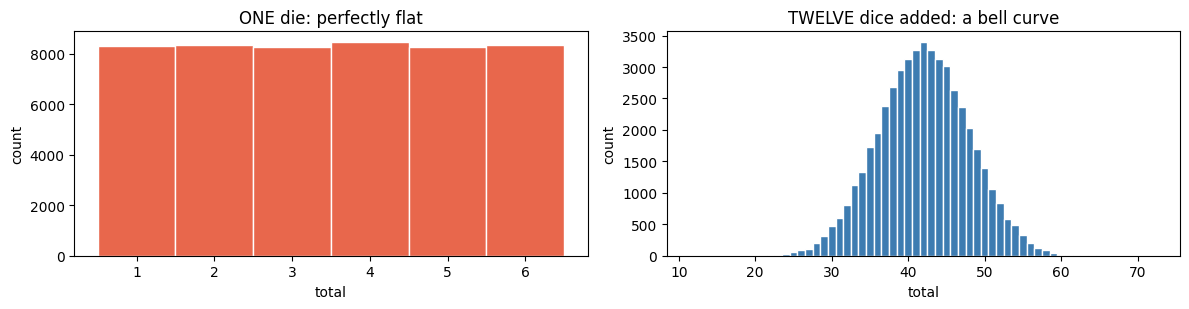

skew of the 12-dice totals: -0.007   (0 = symmetric)


In [3]:
# 12 dice, added together, 50,000 times. Each die is FLAT, not bell-shaped.
rolls = rng.integers(1, 7, size=(50_000, 12)).sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(rng.integers(1, 7, 50_000), bins=np.arange(0.5, 7.5), color="#E8674C",
             edgecolor="white")
axes[0].set_title("ONE die: perfectly flat")
axes[1].hist(rolls, bins=np.arange(11.5, 73.5), color="#3E7CB1", edgecolor="white")
axes[1].set_title("TWELVE dice added: a bell curve")
for ax in axes:
    ax.set_xlabel("total"); ax.set_ylabel("count")
fig.tight_layout()
plt.show()

print(f"skew of the 12-dice totals: {pd.Series(rolls).skew():.3f}   (0 = symmetric)")

Nobody designed that. It falls out of adding independent things together.

> **But the real reason it matters is not that data is usually normal — it often is not.**
> It is that the **averages of repeated samples** are normal almost regardless of the
> underlying shape. That is the Central Limit Theorem, it lands on **Day 27**, and it is the
> engine under every test in the rest of this module.

---
# 2. The empirical rule: 68 – 95 – 99.7

In [6]:
print("exact figures from the maths:")
for k in (1, 2, 3):
    inside = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print(f"  within {k} sd: {inside*100:7.4f}%   outside: 1 in {1/(1-inside):.0f}")

exact figures from the maths:
  within 1 sd: 68.2689%   outside: 1 in 3
  within 2 sd: 95.4500%   outside: 1 in 22
  within 3 sd: 99.7300%   outside: 1 in 370


In [7]:
# confirm by simulation on 2 million draws
d = rng.normal(100, 15, 2_000_000)
print("simulated, mean 100 sd 15:")
for k in (1, 2, 3):
    obs = ((d > 100 - k*15) & (d < 100 + k*15)).mean()
    print(f"  within {k} sd: {obs*100:6.2f}%")

simulated, mean 100 sd 15:
  within 1 sd:  68.24%
  within 2 sd:  95.47%
  within 3 sd:  99.73%


**The "outside" column is the useful one.** A 2σ event happens about once in 22 — unusual,
not remarkable. A 3σ event is once in 370.

> **Use it as a mental ruler.** If the mean commute is 32 minutes with an SD of 6, a
> 50-minute journey is 3σ out — roughly a once-in-370-days event. You can say that in a
> meeting without opening a laptop.

---
# 3. Z-scores — the SD as a ruler

$$z = \frac{\text{value} - \mu}{\sigma}$$

*"How many standard deviations above or below the mean is this?"*

In [8]:
# Standardising turns ANY normal distribution into the SAME one
a = rng.normal(100, 15, 100_000)      # IQ-like
b = rng.normal(5, 0.2, 100_000)       # a machined part, in mm

za = (a - a.mean()) / a.std()
zb = (b - b.mean()) / b.std()

print(f"a: mean {a.mean():7.2f}  sd {a.std():6.3f}   ->  z: mean {za.mean():+.4f}  sd {za.std():.4f}")
print(f"b: mean {b.mean():7.2f}  sd {b.std():6.3f}   ->  z: mean {zb.mean():+.4f}  sd {zb.std():.4f}")
print()
print("Different units, different scales - after standardising, the same ruler.")

a: mean  100.07  sd 15.002   ->  z: mean -0.0000  sd 1.0000
b: mean    5.00  sd  0.199   ->  z: mean +0.0000  sd 1.0000

Different units, different scales - after standardising, the same ruler.


## 3.1 The payoff: comparing things that cannot otherwise be compared

A student scores **78 in Maths** and **65 in Physics**. Which is the better performance?

In [9]:
results = pd.DataFrame({
    "exam":       ["Maths", "Physics"],
    "your_mark":  [78, 65],
    "class_mean": [70, 55],
    "class_sd":   [8, 5],
})
results["z"] = (results["your_mark"] - results["class_mean"]) / results["class_sd"]
results["beat_pct"] = (stats.norm.cdf(results["z"]) * 100).round(1)
print(results.to_string(index=False))
print()
print("The LOWER raw mark is the better performance.")
print("Without z-scores you cannot see that at all.")

   exam  your_mark  class_mean  class_sd   z  beat_pct
  Maths         78          70         8 1.0      84.1
Physics         65          55         5 2.0      97.7

The LOWER raw mark is the better performance.
Without z-scores you cannot see that at all.


## 3.2 `cdf` and `ppf`

| | Takes | Gives | Question it answers |
|---|---|---|---|
| `cdf` | a value | a probability | "what fraction is **below** this?" |
| `ppf` | a probability | a value | "what value sits at this **percentile**?" |

They are inverses of each other.

In [ ]:
# IQ: mean 100, sd 15
print("P(below 130) :", f"{stats.norm.cdf(130, 100, 15)*100:.2f}%")
print("P(above 130) :", f"{(1 - stats.norm.cdf(130, 100, 15))*100:.2f}%")
print("P(85 to 115) :", f"{(stats.norm.cdf(115,100,15) - stats.norm.cdf(85,100,15))*100:.2f}%")
print()
print("95th percentile :", round(stats.norm.ppf(0.95, 100, 15), 2))
print("top 1% starts at:", round(stats.norm.ppf(0.99, 100, 15), 2))

In [ ]:
# THE number you will meet for the rest of this module
print("stats.norm.ppf(0.975) =", round(stats.norm.ppf(0.975), 4), "  <- 1.96")
print("stats.norm.ppf(0.95)  =", round(stats.norm.ppf(0.95), 4))
print()
print("1.96 leaves 2.5% in each tail, so 95% sits in the middle.")
print("That is where '95% confidence interval' comes from. It is not magic -")
print("it is just ppf(0.975), and you will see it in every formula from Day 29.")

---
# 4. ⚠️ When the normal distribution does NOT apply

This is the part people skip, and it is the one that costs money.

In [10]:
# 1,000 salaries: 950 ordinary, 50 executives  (the Day 23 dataset)
# A dedicated generator, so these figures match the slides exactly.
sal_rng = np.random.default_rng(2024)
inc = np.r_[sal_rng.normal(45000, 8000, 950), sal_rng.normal(400000, 60000, 50)]
sal = pd.Series(inc)
m, sd = sal.mean(), sal.std()

print(f"mean {m:,.0f}   sd {sd:,.0f}   skew {sal.skew():.2f}")
print()
print(f"{'check':<18} {'normal says':>12} {'reality':>10}")
for k in (1, 2, 3):
    obs = sal.between(m - k*sd, m + k*sd).mean() * 100
    exp = (stats.norm.cdf(k) - stats.norm.cdf(-k)) * 100
    print(f"{'within ' + str(k) + ' sd':<18} {exp:>11.1f}% {obs:>9.1f}%")
print(f"{'below the mean':<18} {50.0:>11.1f}% {(sal < m).mean()*100:>9.1f}%")
print(f"{'beyond +3 sd':<18} {(1-stats.norm.cdf(3))*100:>11.2f}% {(sal > m + 3*sd).mean()*100:>9.2f}%")

mean 63,039   sd 80,017   skew 4.29

check               normal says    reality
within 1 sd               68.3%      95.0%
within 2 sd               95.4%      95.0%
within 3 sd               99.7%      95.5%
below the mean            50.0%      93.3%
beyond +3 sd              0.13%      4.50%


### ⚠️ Look carefully at the 2σ row

**It passes.** 95.0% against a predicted 95.5%. If that had been the only thing you tested,
you would have concluded the data was normal and moved on.

**It is a coincidence.** Every other check fails badly — the 1σ band is out by 27 percentage
points, and 94% of people sit below the mean when a normal curve says 50%.

> **One passing check is not evidence.** Test several things, and look at the shape.

In [11]:
# What it costs you in practice
print(f"normal model says the 95th percentile is : {m + 1.645*sd:>10,.0f}")
print(f"the actual 95th percentile is            : {sal.quantile(.95):>10,.0f}")
print(f"                                     off by {abs(m + 1.645*sd - sal.quantile(.95)):>10,.0f}")
print()
print(f"and mean - 2sd = {m - 2*sd:,.0f}   <- a NEGATIVE salary")
print()
print(f"Set a 'high earner' threshold from the normal model and you pick")
print(f"{m + 1.645*sd:,.0f}, catching almost nobody, when the real cut-off is")
print(f"{sal.quantile(.95):,.0f}. Every downstream decision inherits that error.")

normal model says the 95th percentile is :    194,667
the actual 95th percentile is            :     78,502
                                     off by    116,165

and mean - 2sd = -96,996   <- a NEGATIVE salary

Set a 'high earner' threshold from the normal model and you pick
194,667, catching almost nobody, when the real cut-off is
78,502. Every downstream decision inherits that error.


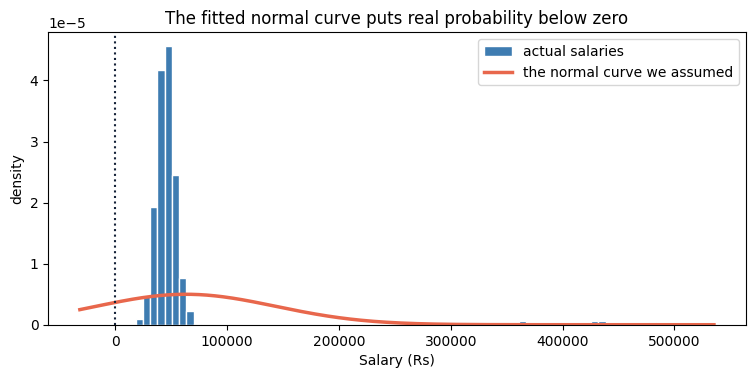

the fitted normal says 21.5% of people earn LESS THAN NOTHING


In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(sal, bins=80, density=True, color="#3E7CB1", edgecolor="white",
        label="actual salaries")
xs = np.linspace(sal.min() - 50_000, sal.max(), 400)
ax.plot(xs, stats.norm.pdf(xs, m, sd), color="#E8674C", linewidth=2.5,
        label="the normal curve we assumed")
ax.axvline(0, color="#152238", linestyle=":", linewidth=1.5)
ax.set_title("The fitted normal curve puts real probability below zero")
ax.set_xlabel("Salary (Rs)"); ax.set_ylabel("density"); ax.legend()
plt.show()

print(f"the fitted normal says {stats.norm.cdf(0, m, sd)*100:.1f}% of people earn LESS THAN NOTHING")

## 4.1 Three ways to check, in order of usefulness

| | How | Note |
|---|---|---|
| **1** | **Plot it** — histogram and Q-Q | By far the most informative |
| **2** | `abs(s.skew()) < 0.5` | A quick numeric screen |
| **3** | `stats.shapiro(s)` | `p > 0.05` = *no evidence against* normal |

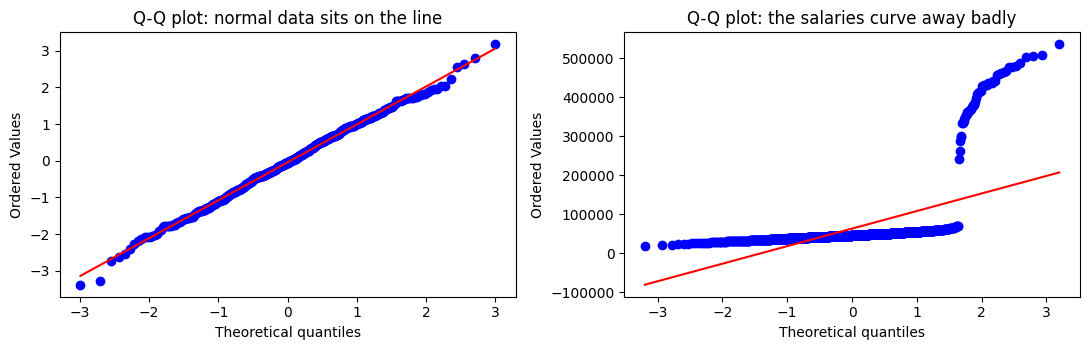

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
stats.probplot(rng.normal(0, 1, 500), plot=axes[0])
axes[0].set_title("Q-Q plot: normal data sits on the line")
stats.probplot(sal, plot=axes[1])
axes[1].set_title("Q-Q plot: the salaries curve away badly")
fig.tight_layout()
plt.show()

# A Q-Q plot compares your data's quantiles against a normal distribution's.
# A straight line means normal. The curve at the top right IS the heavy tail.

In [14]:
for name, x in [("normal data", rng.normal(0, 1, 500)),
                ("the salaries", sal.sample(500, random_state=1))]:
    st, p = stats.shapiro(x)
    verdict = "no evidence against normal" if p > 0.05 else "NOT normal"
    print(f"{name:<14} W={st:.4f}  p={p:.2e}  -> {verdict}")

print()
print("CAREFUL: p > 0.05 does NOT mean 'the data is normal'.")
print("It means you failed to find evidence against it - which on a small")
print("sample is easy. And on 50,000 rows the test rejects normality for a")
print("trivial, meaningless deviation. On large data, trust the plot.")

normal data    W=0.9975  p=6.50e-01  -> no evidence against normal
the salaries   W=0.3269  p=3.89e-39  -> NOT normal

CAREFUL: p > 0.05 does NOT mean 'the data is normal'.
It means you failed to find evidence against it - which on a small
sample is easy. And on 50,000 rows the test rejects normality for a
trivial, meaningless deviation. On large data, trust the plot.


---
# 5. Mini build — a normality check you can trust

In [15]:
def normal_check(s, name="value"):
    """Several independent checks - never just one."""
    s = s.dropna()
    m, sd = s.mean(), s.std()

    bands = {}
    for k in (1, 2, 3):
        obs = s.between(m - k*sd, m + k*sd).mean() * 100
        exp = (stats.norm.cdf(k) - stats.norm.cdf(-k)) * 100
        bands[f"within_{k}sd"] = f"{obs:.1f} vs {exp:.1f}"

    out = {
        "n":          len(s),
        "skew":       round(s.skew(), 2),
        "kurtosis":   round(s.kurt(), 2),
        "below_mean": round((s < m).mean() * 100, 1),      # normal: 50
        "pct95_real": round(s.quantile(.95), 1),
        "pct95_norm": round(m + 1.645 * sd, 1),
        **bands,
    }

    one_sd = s.between(m - sd, m + sd).mean() * 100
    bad = (abs(out["skew"]) > 1
           or abs(out["below_mean"] - 50) > 8
           or abs(one_sd - 68.3) > 6)
    out["verdict"] = "NOT normal - do not use the rule" if bad else "close enough"
    return pd.Series(out, name=name)

In [16]:
heights = pd.Series(rng.normal(170, 10, 1000))
pd.concat([normal_check(heights, "heights"),
           normal_check(sal, "salaries")], axis=1)

,heights,salaries
n,1000,1000
skew,0.04,4.29
kurtosis,-0.14,17.21
below_mean,49.3,93.3
pct95_real,185.3,78502.0
pct95_norm,186.2,194666.6
within_1sd,67.1 vs 68.3,95.0 vs 68.3
within_2sd,95.4 vs 95.4,95.0 vs 95.4
within_3sd,99.8 vs 99.7,95.5 vs 99.7
verdict,close enough,NOT normal - do not use the rule


The salary data **passes the 2σ test and fails this one**. That is the whole point of
checking more than one thing.

---
# 6. Recap — the twelve things to remember

1. Two numbers define the whole curve: **μ** for where, **σ** for how wide.
2. 68% within 1σ, 95% within 2σ, 99.7% within 3σ.
3. The useful form: outside 2σ is **1 in 22**; outside 3σ is **1 in 370**.
4. `z = (value − μ) / σ` — the SD becomes a **unit of measurement**.
5. Standardising turns **any** normal curve into the same one.
6. A lower raw mark can be the better performance. Only z shows it.
7. `cdf`: value in, probability out. `ppf`: probability in, value out.
8. **1.96 is not magic** — it is `ppf(0.975)`, leaving 95% in the middle.
9. ⚠️ Real data is often **not** normal. Income, delays, file sizes.
10. On the salary data the **2σ check passed by pure coincidence**.
11. So test several things, and look at the shape. One pass proves nothing.
12. `p > 0.05` means **no evidence against** normal — not that it is normal.

---

### 📝 Now open **`Day24_Practice_Questions.ipynb`**.

### Homework
- Run `normal_check` on every numeric column of your Day 21 project data and say which are
  normal.
- Find your own two-exam example and compute both z-scores.
- Use `ppf` to find the mark that would put a student in the top 5%.

### Next class — Topic 2.5: Binomial & Poisson
The distributions for **counting** things — how many clicks out of 1,000, how many failures
this month. Discrete, not continuous.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*